# Phân tích dữ liệu (EDA) – Music Genre

**Mục tiêu:** tìm xem feature nào phân biệt được thể loại nhạc (`Class`, 11 lớp) và có bẫy nào cần lưu ý khi dựng mô hình.

Dữ liệu dùng: `data/clean/train_clean.csv` (đã làm sạch ở `NoteBook/cleaning/overview.ipynb`).

## Thư viện sử dụng

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid")

## 1. Đọc dữ liệu và phân phối nhãn `Class`

In [2]:
# key, time_signature là biến phân loại -> đọc dạng chuỗi (CSV không lưu kiểu dữ liệu)
df = pd.read_csv(Path(r"..\..\data\clean\train_clean.csv"), dtype={"key": str, "time_signature": str})
test = pd.read_csv(Path(r"..\..\data\clean\test_clean.csv"), dtype={"key": str, "time_signature": str})
print(df.shape, test.shape)
df.head()

(14396, 17) (3600, 16)


,Artist Name,Popularity,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms,time_signature,Class,instrumentalness_missing
0,Marina Maximilian,37.0,0.334,0.536,9,-6.649,0,0.0381,0.378000,0.0000,0.106,0.235,152.429,204947.0,4,9,1
1,The Black Keys,67.0,0.725,0.747,11,-5.545,1,0.0876,0.027200,0.0468,0.104,0.380,132.921,191956.0,4,6,0
2,Royal & the Serpent,44.0,0.584,0.804,7,-6.094,1,0.0619,0.000968,0.6350,0.284,0.635,159.953,161037.0,4,10,0
3,Detroit Blues Band,12.0,0.515,0.308,0,-14.711,1,0.0312,0.907000,0.0213,0.300,0.501,172.472,298093.0,3,2,0
4,Coast Contra,48.0,0.565,0.777,6,-5.096,0,0.2490,0.183000,0.0000,0.211,0.619,88.311,254145.0,4,5,1


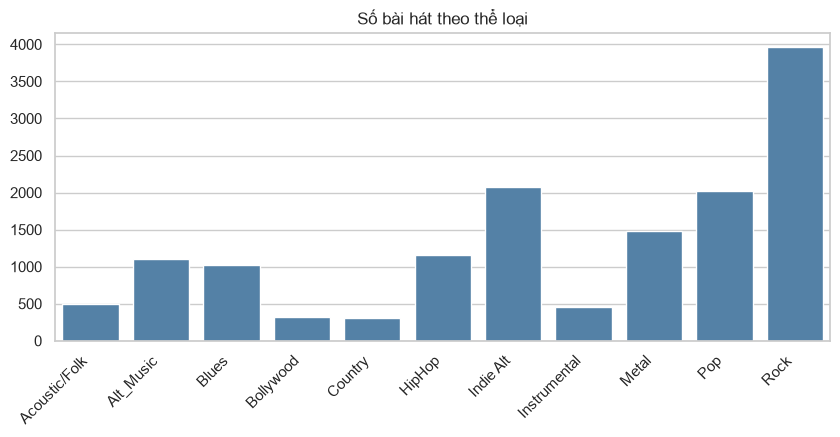

In [3]:
# Tên thể loại lấy từ mô tả Kaggle gốc (cần đối chiếu lại với nguồn)
GENRE = {0: "Acoustic/Folk", 1: "Alt_Music", 2: "Blues", 3: "Bollywood", 4: "Country", 5: "HipHop",
         6: "Indie Alt", 7: "Instrumental", 8: "Metal", 9: "Pop", 10: "Rock"}

order = sorted(GENRE)
counts = df["Class"].value_counts().reindex(order)

plt.figure(figsize=(10, 4))
sns.barplot(x=[GENRE[i] for i in order], y=counts.values, color="steelblue")
plt.xticks(rotation=45, ha="right")
plt.title("Số bài hát theo thể loại")
plt.show()

**Nhận xét:**
- Dữ liệu **mất cân bằng mạnh**: Rock (lớp 10) chiếm 27,5% (3.959 bài), Indie Alt 14,4% và Pop 14,0%; ngược lại Bollywood và Country chỉ 2,2% (~310–320 bài), chênh khoảng 12,8 lần (3.959 so với 310).
- Một mô hình luôn đoán "Rock" đã đạt ~27,5% accuracy, nên accuracy không đủ để đánh giá. Cần dùng **F1-macro** (và xem recall từng lớp), đồng thời chia dữ liệu có `stratify`.
- Các lớp nhỏ (Bollywood, Country, Acoustic/Folk, Instrumental) ít mẫu nhưng lại có đặc trưng khá riêng (xem mục 3), nên vẫn có khả năng học được nếu dùng `class_weight` hoặc oversampling nhẹ.

## 2. Phân tích đơn biến

Xem hình dạng phân phối và độ lệch (skewness) của từng feature liên tục để biết cột nào cần biến đổi/scale.

In [4]:
NUM = ["Popularity", "danceability", "energy", "loudness", "speechiness", "acousticness",
       "instrumentalness", "liveness", "valence", "tempo", "duration_ms"]

df[NUM].describe().T.assign(skew=df[NUM].skew())

,count,mean,std,min,25%,50%,75%,max,skew
Popularity,14396.0,44.513059,17.216466,1.00000,33.000000,44.000000,56.00000,100.000,0.078797
danceability,14396.0,0.543105,0.165517,0.05960,0.432000,0.545000,0.65800,0.989,-0.075651
energy,14396.0,0.662422,0.235967,0.00121,0.508000,0.699000,0.86100,1.000,-0.656698
loudness,14396.0,-7.900852,4.057362,-39.95200,-9.538000,-7.013500,-5.16200,1.342,-1.748073
speechiness,14396.0,0.080181,0.085157,0.02250,0.034800,0.047100,0.08310,0.955,3.113395
acousticness,14396.0,0.246746,0.310922,0.00000,0.004280,0.081450,0.43225,0.996,1.108933
instrumentalness,14396.0,0.134314,0.275118,0.00000,0.000001,0.000328,0.05760,0.996,1.970628
liveness,14396.0,0.195782,0.159258,0.01190,0.097275,0.129000,0.25600,0.992,2.178265
valence,14396.0,0.486379,0.239476,0.02150,0.299000,0.480500,0.67200,0.986,0.088687
tempo,14396.0,122.695372,29.538490,30.55700,99.799000,120.060000,141.98825,217.416,0.376507


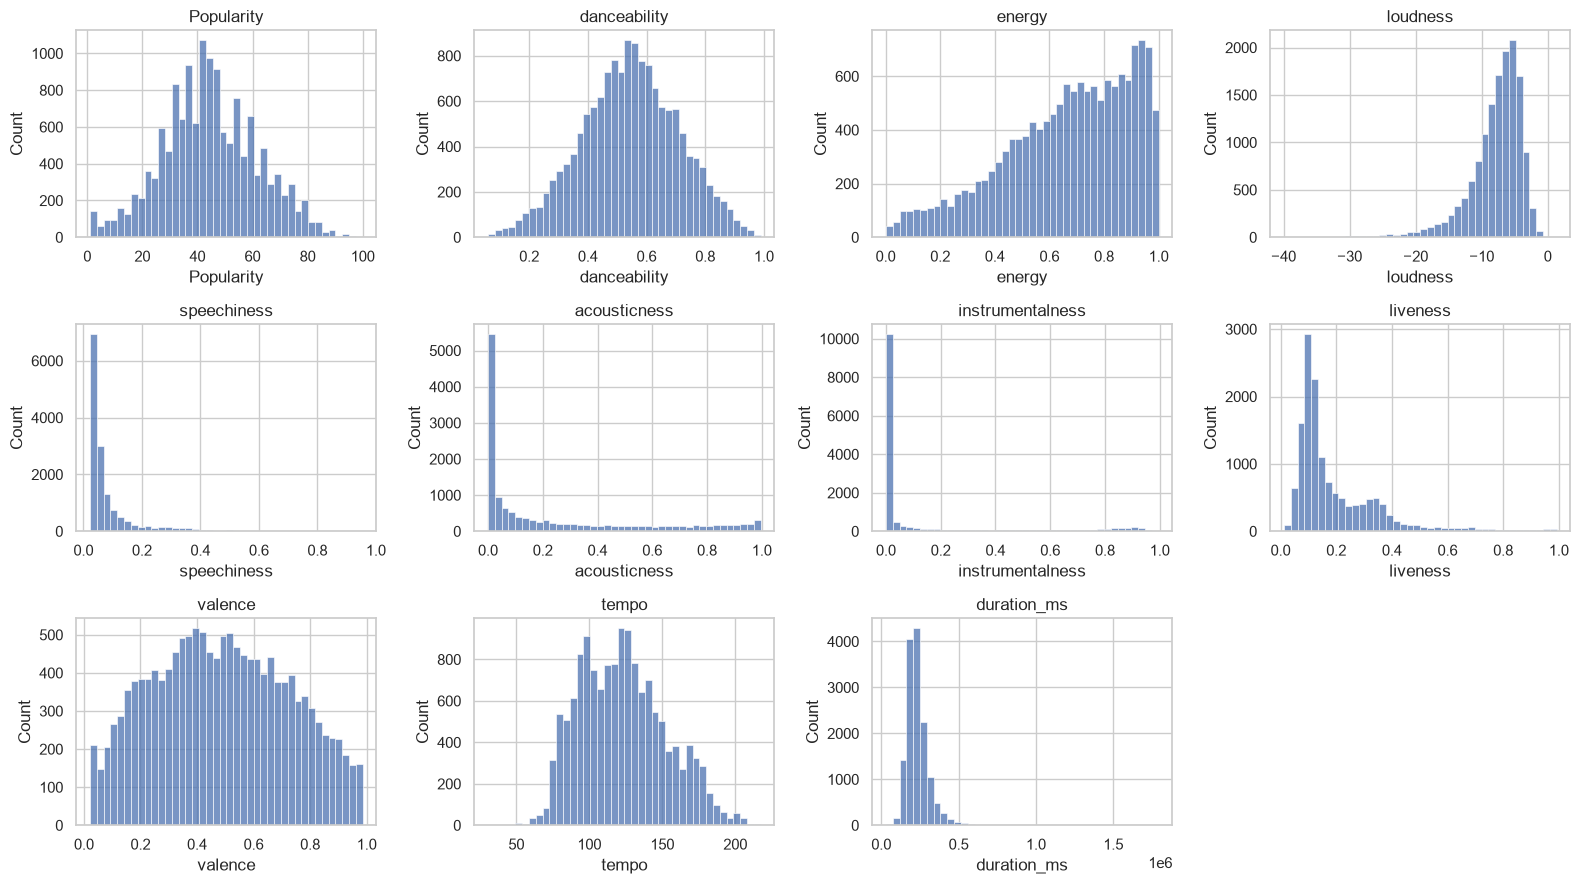

In [5]:
fig, axes = plt.subplots(3, 4, figsize=(16, 9))
for ax, col in zip(axes.ravel(), NUM):
    sns.histplot(df[col], bins=40, ax=ax)
    ax.set_title(col)
for ax in axes.ravel()[len(NUM):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

**Nhận xét:**
- **Gần đối xứng**: `Popularity`, `danceability`, `valence` (skew ≈ 0), `tempo` (0,38) và `energy` (−0,66, lệch nhẹ về phía giá trị cao). Không cần biến đổi nhiều.
- **Lệch phải mạnh**: `duration_ms` (3,80), `speechiness` (3,11), `liveness` (2,18), `instrumentalness` (1,97) và `acousticness` (1,11). **Lệch trái**: `loudness` (−1,75).
- `speechiness`, `instrumentalness` dồn gần như toàn bộ về 0 (trung vị `instrumentalness` chỉ 0,0003) và chỉ có một cụm nhỏ ở vùng 0,8–1,0, nên về bản chất là biến "gần nhị phân" hơn là liên tục. `acousticness` dồn ở 0 rồi trải đều đến 1.
- **Giá trị cực trị** nhưng hợp lý về mặt âm nhạc nên giữ lại: 82 bài có `loudness` < −25 dB (thấp nhất −39,95), 73 bài dài hơn 10 phút (dài nhất ~30 phút), 13 bài có `speechiness` > 0,66 (gần như toàn lời nói). Với mô hình tuyến tính/khoảng cách nên dùng log hoặc `RobustScaler`; mô hình cây không cần.
- `tempo` có dạng hai đỉnh (~100 và ~125 BPM), nhiều khả năng do cách Spotify ước lượng nhịp, không ảnh hưởng lớn.

## 3. Feature × `Class` (phần trọng tâm)

Feature nào có phân phối khác nhau rõ giữa các thể loại thì có khả năng phân loại tốt.

In [6]:
df["Genre"] = df["Class"].map(GENRE)
genre_order = [GENRE[i] for i in order]

df.groupby("Genre")[NUM].mean().reindex(genre_order).round(2)

,Popularity,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms
Genre,,,,,,,,,,,
Acoustic/Folk,38.89,0.53,0.44,-10.15,0.04,0.58,0.08,0.15,0.39,118.90,246109.25
Alt_Music,46.06,0.54,0.69,-7.73,0.07,0.19,0.17,0.19,0.51,125.18,224334.50
Blues,33.21,0.56,0.57,-9.08,0.06,0.39,0.09,0.21,0.61,122.43,248134.23
Bollywood,26.69,0.50,0.53,-10.14,0.08,0.73,0.10,0.24,0.63,114.11,290856.38
Country,55.98,0.59,0.60,-8.50,0.04,0.31,0.01,0.17,0.62,123.73,202878.85
HipHop,48.47,0.72,0.64,-7.48,0.24,0.20,0.02,0.20,0.55,117.90,206552.66
Indie Alt,41.55,0.55,0.65,-8.23,0.07,0.23,0.24,0.18,0.49,123.63,227194.83
Instrumental,41.68,0.43,0.16,-18.74,0.04,0.91,0.75,0.13,0.23,107.17,249897.02
Metal,42.06,0.41,0.88,-5.86,0.09,0.03,0.22,0.23,0.32,127.77,271536.31


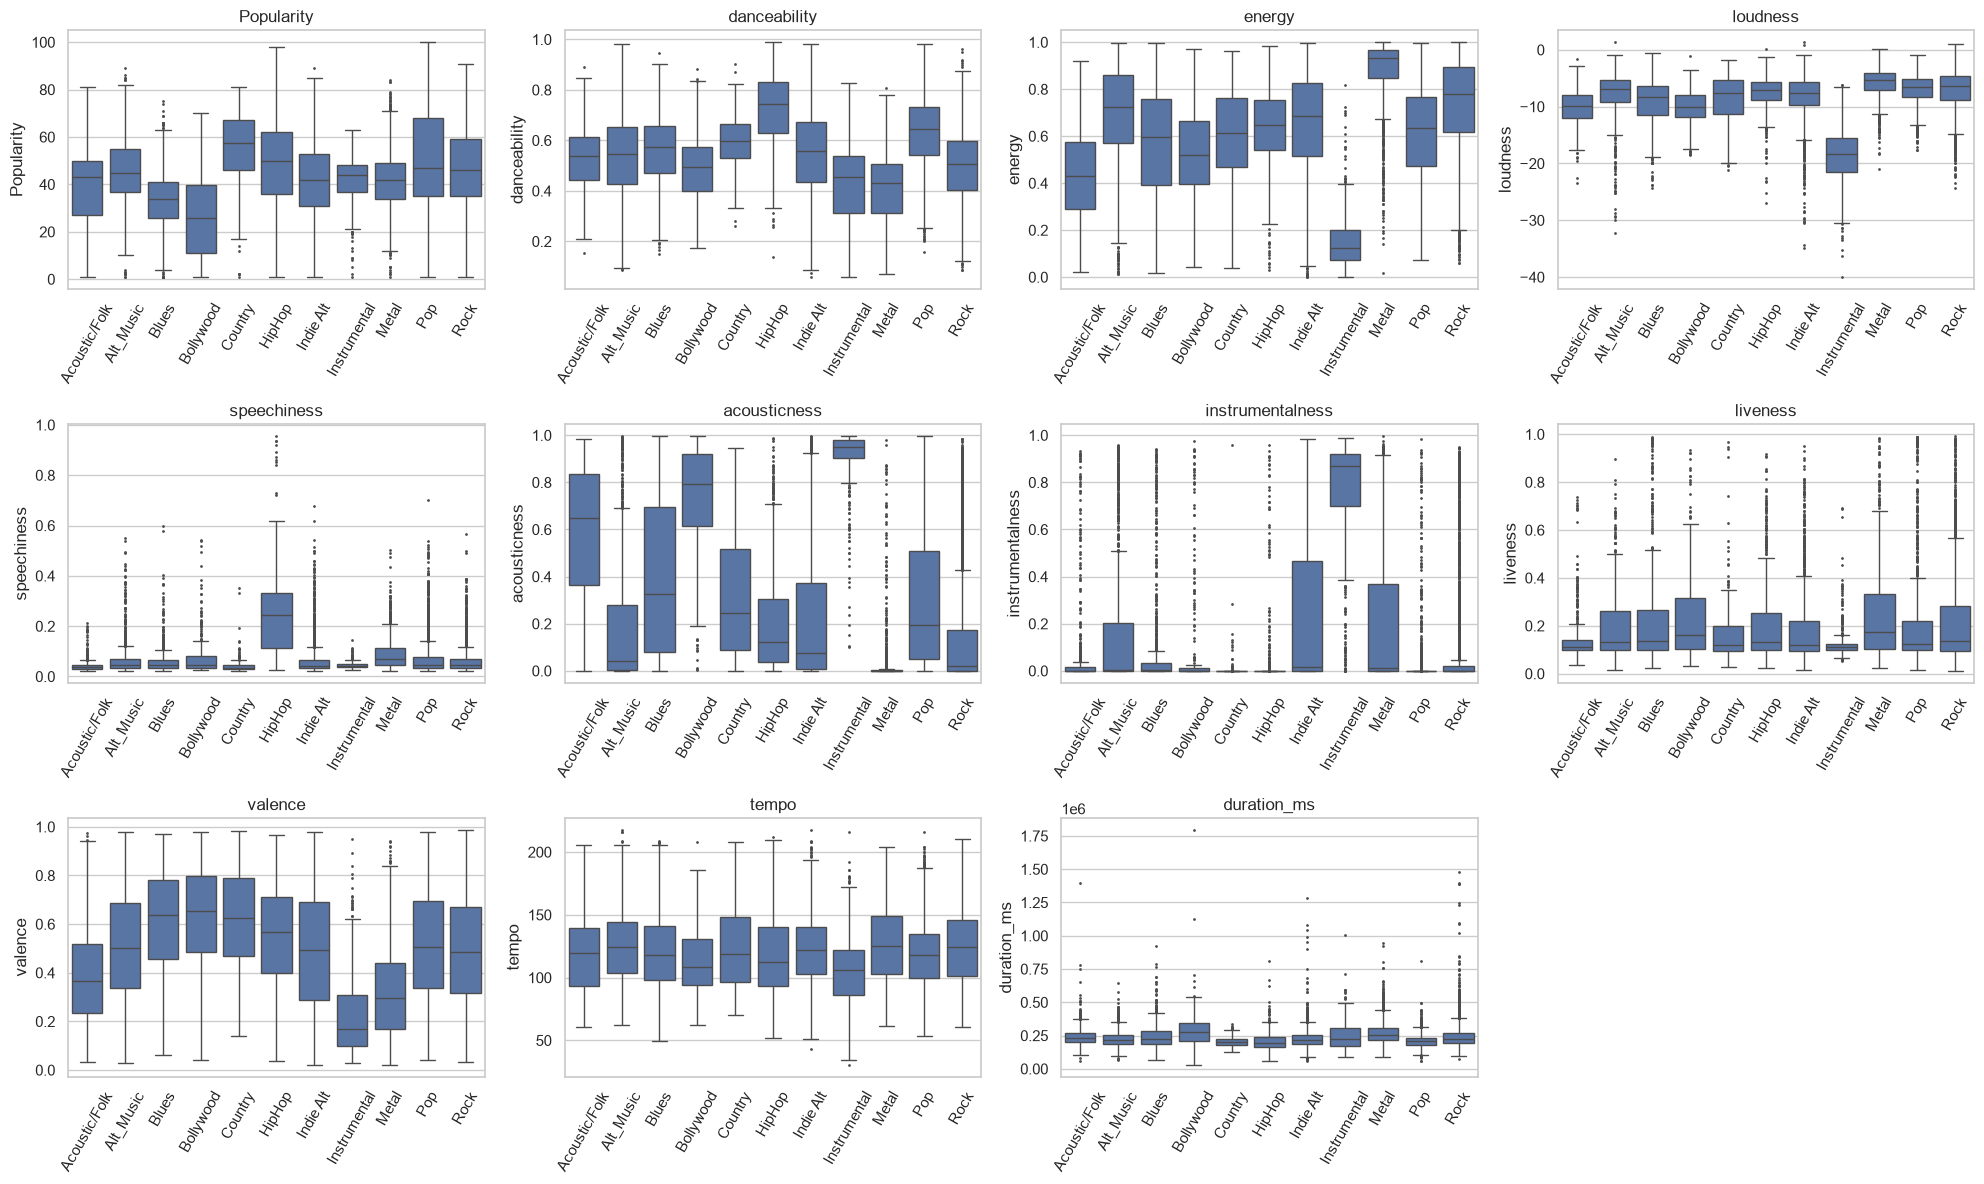

In [7]:
fig, axes = plt.subplots(3, 4, figsize=(20, 12))
for ax, col in zip(axes.ravel(), NUM):
    sns.boxplot(data=df, x="Genre", y=col, order=genre_order, ax=ax, fliersize=1)
    ax.set_title(col)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=60)
for ax in axes.ravel()[len(NUM):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

In [8]:
# Mức độ "giải thích" của Class đối với từng feature: eta^2 = phương sai giữa các lớp / tổng phương sai
def eta_squared(col):
    groups = [g[col].values for _, g in df.groupby("Class")]
    grand = df[col].mean()
    ss_between = sum(len(g) * (g.mean() - grand) ** 2 for g in groups)
    ss_total = ((df[col] - grand) ** 2).sum()
    return ss_between / ss_total

eta = pd.Series({c: eta_squared(c) for c in NUM}).sort_values(ascending=False).round(3)
eta.to_frame("eta_squared")

,eta_squared
acousticness,0.346
speechiness,0.324
energy,0.314
loudness,0.300
instrumentalness,0.242
danceability,0.241
valence,0.136
Popularity,0.101
duration_ms,0.061
tempo,0.022


**Nhận xét:** (`eta²` = tỉ lệ phương sai của feature được giải thích bởi `Class`, càng cao càng tách lớp tốt)
- **Tách lớp tốt**: `acousticness` (0,35), `speechiness` (0,32), `energy` (0,31), `loudness` (0,30), tiếp theo là `instrumentalness` (0,24) và `danceability` (0,24).
- **Tách lớp yếu**: `valence` (0,14), `Popularity` (0,10), `duration_ms` (0,06) và gần như vô dụng là `tempo` (0,02), `liveness` (0,02).
- **Lớp có "dấu vân tay" rõ**:
  - *Instrumental*: `energy` 0,16, `acousticness` 0,91, `instrumentalness` 0,75, `loudness` −18,7 dB, tất cả đều khác hẳn các lớp còn lại, nên là lớp dễ nhất.
  - *Metal*: `energy` 0,88, `acousticness` 0,03, `valence` thấp (0,32), `loudness` lớn nhất (−5,9 dB).
  - *HipHop*: `speechiness` 0,24 (các lớp khác ≤ 0,09) và `danceability` cao nhất (0,72).
  - *Country*: `Popularity` cao nhất (~56); *Bollywood*: `Popularity` thấp nhất (~27), `acousticness` cao (0,73) và bài dài nhất (~291 giây).
  - *Acoustic/Folk*: `acousticness` ~0,58 và `energy` thấp (0,44).
- **Các lớp dễ nhầm nhau**: *Alt_Music*, *Indie Alt*, *Rock* và *Pop* có giá trị trung bình rất gần nhau ở hầu hết feature (ví dụ Rock/Alt_Music: `energy` 0,73/0,69, `acousticness` 0,14/0,19) và hộp boxplot chồng lấn nhiều. Đây là nhóm sẽ kéo F1 xuống.
- Lưu ý: cột `Popularity` trong bảng mean đã gồm các giá trị điền median (44) ở bước cleaning nên hơi lệch so với raw.

## 4. Tương quan giữa các feature

Tìm các cặp feature chồng lấn thông tin (đa cộng tuyến), quan trọng với mô hình tuyến tính.

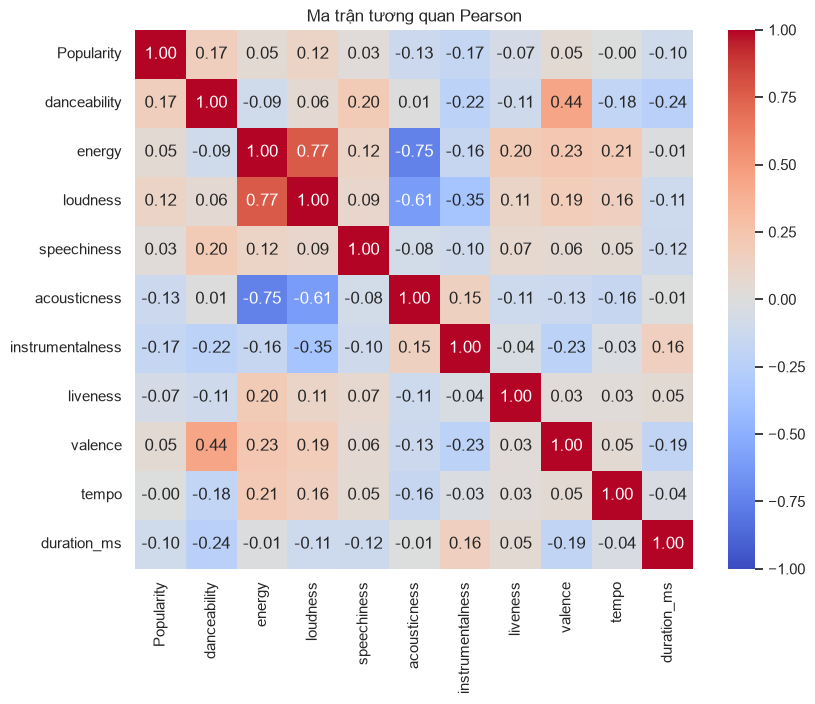

In [9]:
corr = df[NUM].corr()

plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Ma trận tương quan Pearson")
plt.show()

**Nhận xét:**
- Có **một cụm đa cộng tuyến**: `energy`–`loudness` (+0,77), `energy`–`acousticness` (−0,75), `loudness`–`acousticness` (−0,61). Ba biến này cùng mô tả "mức độ mạnh/ồn của bài" nên thông tin chồng lấn nhiều.
- Các cặp còn lại đều yếu: `danceability`–`valence` (+0,44), `loudness`–`instrumentalness` (−0,35), còn lại |r| < 0,25.
- Với **mô hình cây/boosting** thì không cần xử lý. Với **mô hình tuyến tính, SVM, KNN** nên dùng regularization hoặc chỉ giữ 1–2 biến trong cụm trên (ví dụ bỏ `loudness`).
- Vì `eta²` của `energy`, `loudness`, `acousticness` đều cao (0,30–0,35), không nên loại cả cụm.

## 5. Biến rời rạc × `Class`

Gồm `key`, `mode`, `time_signature` và cờ `instrumentalness_missing`. Bảng là tỉ lệ (%) theo từng thể loại.

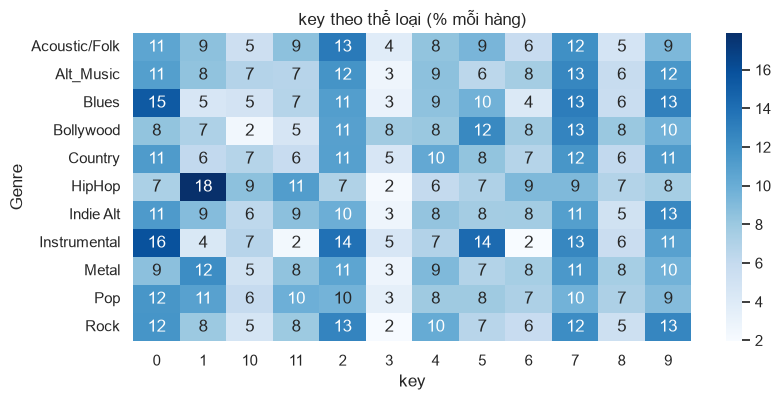

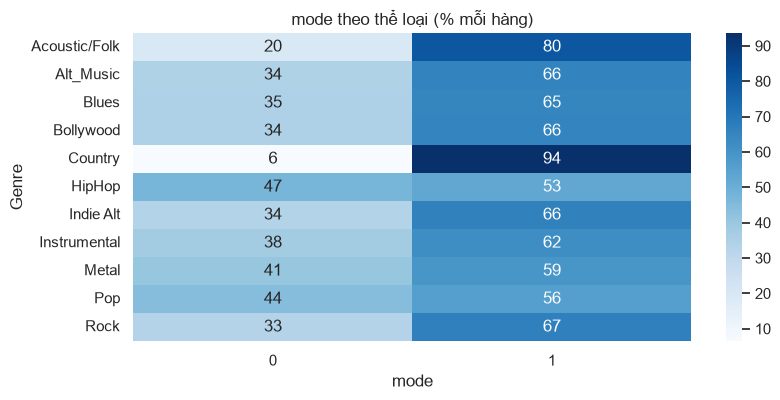

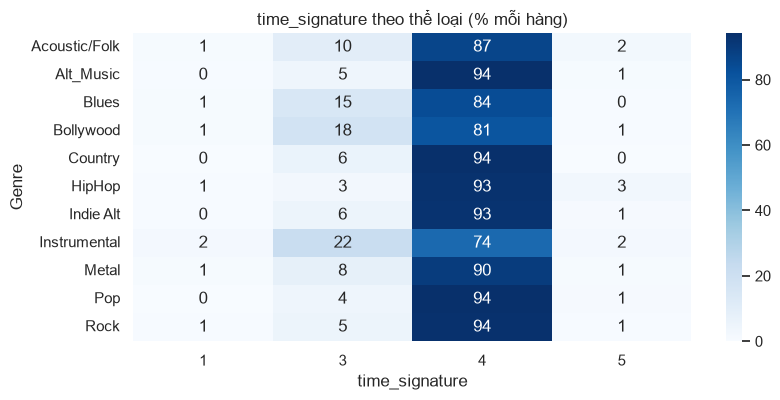

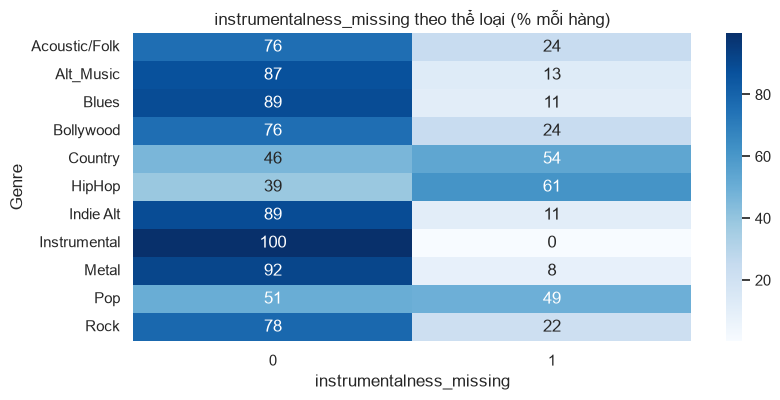

In [10]:
for col in ["key", "mode", "time_signature", "instrumentalness_missing"]:
    ct = pd.crosstab(df["Genre"], df[col], normalize="index").reindex(genre_order) * 100
    plt.figure(figsize=(9, 4))
    sns.heatmap(ct, annot=True, fmt=".0f", cmap="Blues")
    plt.title(f"{col} theo thể loại (% mỗi hàng)")
    plt.show()

In [11]:
# Cramér's V giữa từng biến rời rạc và Class (0 = độc lập, 1 = phụ thuộc hoàn toàn)
from scipy.stats import chi2_contingency

def cramers_v(x, y):
    table = pd.crosstab(x, y)
    chi2 = chi2_contingency(table)[0]
    return np.sqrt(chi2 / table.values.sum() / (min(table.shape) - 1))

pd.Series({c: cramers_v(df[c], df["Class"]) for c in ["key", "mode", "time_signature", "instrumentalness_missing"]}
          ).round(3).sort_values(ascending=False).to_frame("cramers_v")

,cramers_v
instrumentalness_missing,0.411
mode,0.152
time_signature,0.110
key,0.065


**Nhận xét:** (đo bằng Cramér's V ở ô bên dưới)
- `instrumentalness_missing` là biến rời rạc **mạnh nhất** (V ≈ 0,41): tỉ lệ thiếu thay đổi rất mạnh theo lớp, từ 0% (Instrumental) và 8–13% (Metal, Alt_Music, Blues, Indie Alt) lên 54% (Country), 61% (HipHop), 49% (Pop). Giữ cờ này khi mô hình hóa là quyết định đúng.
- `mode`: V ≈ 0,15. Country gần như toàn **trưởng** (94%), Acoustic/Folk 80%, còn HipHop (53%), Metal (59%) và Pop (56%) gần mức ngẫu nhiên.
- `time_signature`: V ≈ 0,11. Phần lớn là nhịp 4/4, nhưng nhịp khác 4 chiếm tỉ lệ cao hơn ở Instrumental (26%), Bollywood (19%), Blues (16%), Acoustic/Folk (13%) so với ~6% ở Rock, Pop, Country, Alt_Music.
- `key`: V ≈ 0,07, **gần như không có thông tin**. Tỉ lệ `key = 0` (nốt C, vốn là ô thiếu) giữa các lớp chỉ dao động 7–16%, không thấy kiểu thiếu có hệ thống theo lớp như `instrumentalness`, nên chưa có bằng chứng bác bỏ giả định "NaN = key 0" ở bước cleaning (nhưng cũng chưa chứng minh được nó đúng).

In [12]:
raw = pd.read_csv(Path(r"..\..\data\raw\train.csv"))
raw_test = pd.read_csv(Path(r"..\..\data\raw\test.csv"))

was_minute = raw["duration_in min/ms"] < 30
print((pd.crosstab(raw["Class"].map(GENRE), was_minute, normalize="index") * 100).round(1))
print("Tỉ lệ dòng ghi bằng phút - train: %.1f%%, test: %.1f%%"
      % (was_minute.mean() * 100, (raw_test["duration_in min/ms"] < 30).mean() * 100))

duration_in min/ms  False  True 
Class                           
Acoustic/Folk         0.0  100.0
Alt_Music           100.0    0.0
Blues               100.0    0.0
Bollywood             0.0  100.0
Country               0.0  100.0
HipHop              100.0    0.0
Indie Alt           100.0    0.0
Instrumental          0.0  100.0
Metal               100.0    0.0
Pop                  83.2   16.8
Rock                 96.4    3.6
Tỉ lệ dòng ghi bằng phút - train: 14.4%, test: 14.0%


**Nhận xét:**
- Dòng ghi `duration` bằng **phút** chiếm **100%** ở Acoustic/Folk, Bollywood, Country, Instrumental và **0%** ở Alt_Music, Blues, HipHop, Indie Alt, Metal; còn lại là Pop (16,8%) và Rock (3,6%). Tức đơn vị ghi chép phụ thuộc vào **nguồn dữ liệu** của từng lớp, không phải tính chất âm nhạc.
- Tỉ lệ này ở test gần như giống train (14,0% so với 14,4%), nên cờ này **sẽ có tác dụng cả trên test** và có thể là một trong những feature mạnh nhất cho 4 lớp trên.
- Đây là một dạng **rò rỉ nhãn qua cách thu thập dữ liệu**: tăng điểm trên tập này nhưng không phản ánh khả năng nhận diện thể loại thật sự. Bước cleaning đã đổi sang ms nên tín hiệu này đã mất. **Cần nhóm quyết định** có tạo cờ `duration_was_minute` hay không và nói rõ trong báo cáo nếu dùng.

## 6. Artist

Có nên dùng `Artist Name` làm feature không? Xem mức độ phủ giữa train và test, và artist có "trung thành" với một thể loại hay không.

In [13]:
per_artist = df.groupby("Artist Name")["Class"].agg(n="size", n_class="nunique")

print("Số artist trong train:", len(per_artist))
print("Artist chỉ có 1 bài: %.1f%%" % ((per_artist["n"] == 1).mean() * 100))
print("Bài test có artist đã xuất hiện trong train: %.1f%%"
      % (test["Artist Name"].isin(df["Artist Name"]).mean() * 100))

multi = per_artist[per_artist["n"] >= 3]
print("Artist có >= 3 bài: %d, trong đó chỉ thuộc 1 thể loại: %.1f%%"
      % (len(multi), (multi["n_class"] == 1).mean() * 100))

Số artist trong train: 7913
Artist chỉ có 1 bài: 66.8%
Bài test có artist đã xuất hiện trong train: 63.8%
Artist có >= 3 bài: 1215, trong đó chỉ thuộc 1 thể loại: 37.4%


**Nhận xét:**
- 14.396 bài thuộc **7.913 artist** (~1,8 bài/artist); **66,8% artist chỉ có đúng 1 bài**, nên phần lớn artist không đủ dữ liệu để học riêng.
- **63,8% bài test có artist đã xuất hiện trong train**, nên có thể tận dụng nhưng 36% còn lại là artist hoàn toàn mới.
- Trong 1.215 artist có từ 3 bài trở lên, chỉ **37,4% chỉ thuộc một thể loại**. Nghĩa là artist có liên hệ với thể loại nhưng **không đủ ổn định** để dùng như nhãn.
- Không nên One-Hot `Artist Name` (7.913 cột). Hướng khả thi: **target encoding có làm mượt (smoothing) và tính out-of-fold** để tránh rò rỉ, kèm một feature đếm số bài của artist. Cần cẩn thận khi chia train/validation vì cùng artist (và cùng bài) có thể rơi vào cả hai tập.

## 7. Kết luận và gợi ý cho bước feature engineering

| Nhóm | Kết luận từ EDA | Hướng xử lý |
|---|---|---|
| Biến lệch mạnh | `duration_ms` (skew 3,8), `speechiness` (3,1), `liveness` (2,2), `instrumentalness` (2,0), `loudness` (−1,7), `acousticness` (1,1) | `log1p`/`PowerTransformer` hoặc `RobustScaler` cho mô hình tuyến tính/KNN/SVM; mô hình cây giữ nguyên. Không xóa giá trị cực trị vì đều hợp lý |
| Feature tách lớp tốt | `acousticness`, `speechiness`, `energy`, `loudness` (eta² 0,30–0,35); `instrumentalness`, `danceability` (0,24); `instrumentalness_missing` (V 0,41) | Giữ toàn bộ |
| Feature tách lớp yếu | `tempo`, `liveness` (eta² 0,02), `duration_ms` (0,06), `key` (V 0,07) | Giữ cho mô hình cây; có thể thử bỏ khi dùng mô hình tuyến tính |
| Chồng lấn | `energy`–`loudness` (0,77), `energy`–`acousticness` (−0,75), `loudness`–`acousticness` (−0,61) | Regularization hoặc bỏ bớt `loudness` với mô hình tuyến tính; cây không cần |
| `key`, `time_signature` | Yếu, nhưng cần coi là biến phân loại | One-Hot (đọc bằng `dtype=str`); gộp `time_signature = 1` (87 dòng) vào nhóm hiếm |
| `Artist Name` | 7.913 artist, 66,8% chỉ 1 bài, 63,8% bài test có artist trong train, nhãn không ổn định | Không One-Hot. Thử target encoding out-of-fold có smoothing + số bài của artist |
| Cờ `duration_was_minute` | Gần như tách được 4 lớp (100% ở Acoustic/Folk, Bollywood, Country, Instrumental) và đúng cả trên test, nhưng là artifact của nguồn dữ liệu | **Nhóm quyết định** có dùng không; nếu dùng phải nêu rõ trong báo cáo |
| Lớp khó | Alt_Music, Indie Alt, Rock, Pop chồng lấn nhiều | Xem confusion matrix ở bước baseline |
| Chia dữ liệu | Mất cân bằng (27,5% đến 2,2%), nhiều bài trùng và đa nhãn | `stratify` theo `Class`; `GroupKFold` theo bài (cần `Track Name` từ file raw vì file clean đã bỏ cột này) hoặc theo artist |
| Metric | Lớp nhỏ vẫn quan trọng | F1-macro, kèm `class_weight` |